# Coverage and missingness

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
chars = char_names()
lf = chars_lazy()
lf.select(rows=pl.len(), firms=pl.col("permno").n_unique(), months=pl.col("DATE").n_unique(),
          first=pl.col("DATE").min(), last=pl.col("DATE").max()).collect()

rows,firms,months,first,last
u32,u32,u32,i64,i64
2383384,22523,346,19900228,20181130


## Firm-months per month: all, after size/zerotrade filter, with a same-month return

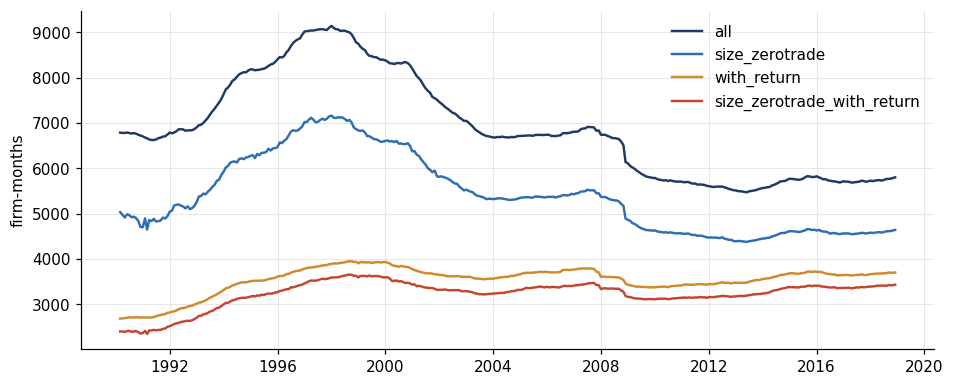

all,size_zerotrade,size_zerotrade_with_return,with_return
f64,f64,f64,f64
6888.0000,5404.0000,3231.0000,3538.0000


In [3]:
ret_keys = returns_lazy().select("permno", "ym")
all_m = lf.group_by("DATE").len().rename({"len": "all"})
filt = size_zerotrade_filter(lf)
filt_m = filt.group_by("DATE").len().rename({"len": "size_zerotrade"})
filt_r = filt.join(ret_keys, on=["permno", "ym"], how="semi").group_by("DATE").len().rename({"len": "size_zerotrade_with_return"})
any_r = lf.join(ret_keys, on=["permno", "ym"], how="semi").group_by("DATE").len().rename({"len": "with_return"})
counts = all_m.join(filt_m, on="DATE").join(filt_r, on="DATE").join(any_r, on="DATE").sort("DATE").collect()
dates = pl.Series(counts["DATE"].cast(pl.String)).str.to_date("%Y%m%d")
fig, ax = plt.subplots(figsize=(10, 4))
for col, c in zip(["all", "size_zerotrade", "with_return", "size_zerotrade_with_return"], ["#1f3b63", BLUE, "#d08a2c", "#c4462f"]):
    ax.plot(dates, counts[col], lw=1.6, color=c, label=col)
ax.set_ylabel("firm-months"); ax.legend(frameon=False); plt.show()
counts.select(pl.exclude("DATE").mean().round(0))

## In-sample universe used below (size/zerotrade filter, same-month return, DATE <= IS end)

In [4]:
df = add_n_missing(is_universe(), chars)
df.select(rows=pl.len(), firms=pl.col("permno").n_unique(), months=pl.col("DATE").n_unique())

rows,firms,months
u32,u32,u32
607822,6223,191


## Missing share per characteristic

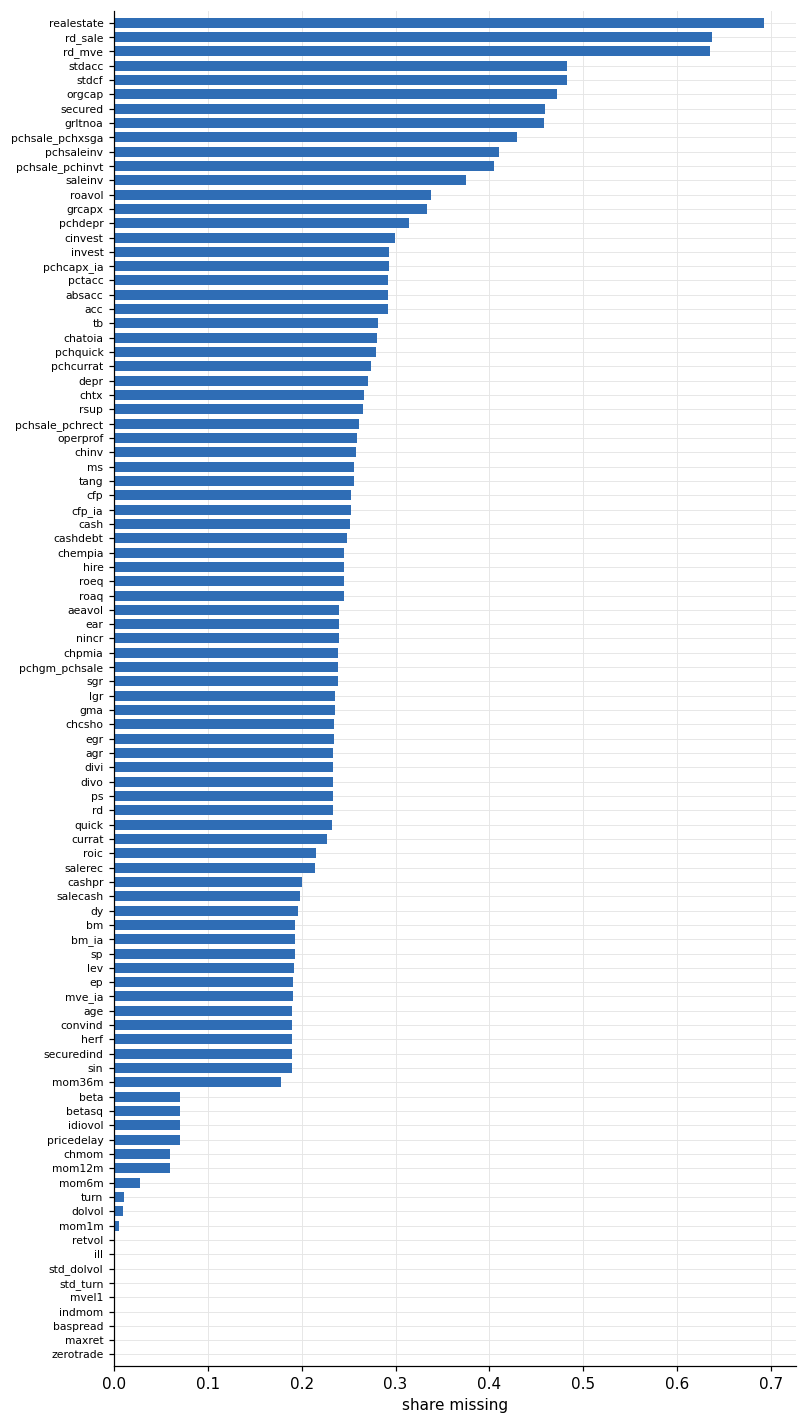

char,missing
str,f64
"""realestate""",0.6922
"""rd_sale""",0.6368
"""rd_mve""",0.6354
"""stdacc""",0.4832
"""stdcf""",0.4832
"""orgcap""",0.4722
"""secured""",0.4588
"""grltnoa""",0.4584
"""pchsale_pchxsga""",0.4293


In [5]:
miss = (df.select([pl.col(c).is_null().mean().alias(c) for c in chars])
          .transpose(include_header=True, header_name="char", column_names=["missing"])
          .sort("missing", descending=True))
fig, ax = plt.subplots(figsize=(8, 16))
ax.barh(miss["char"][::-1], miss["missing"][::-1], color=BLUE, height=0.7)
ax.set_xlabel("share missing"); ax.tick_params(axis="y", labelsize=7); ax.margins(y=0.005); plt.show()
miss

## Missing share by year

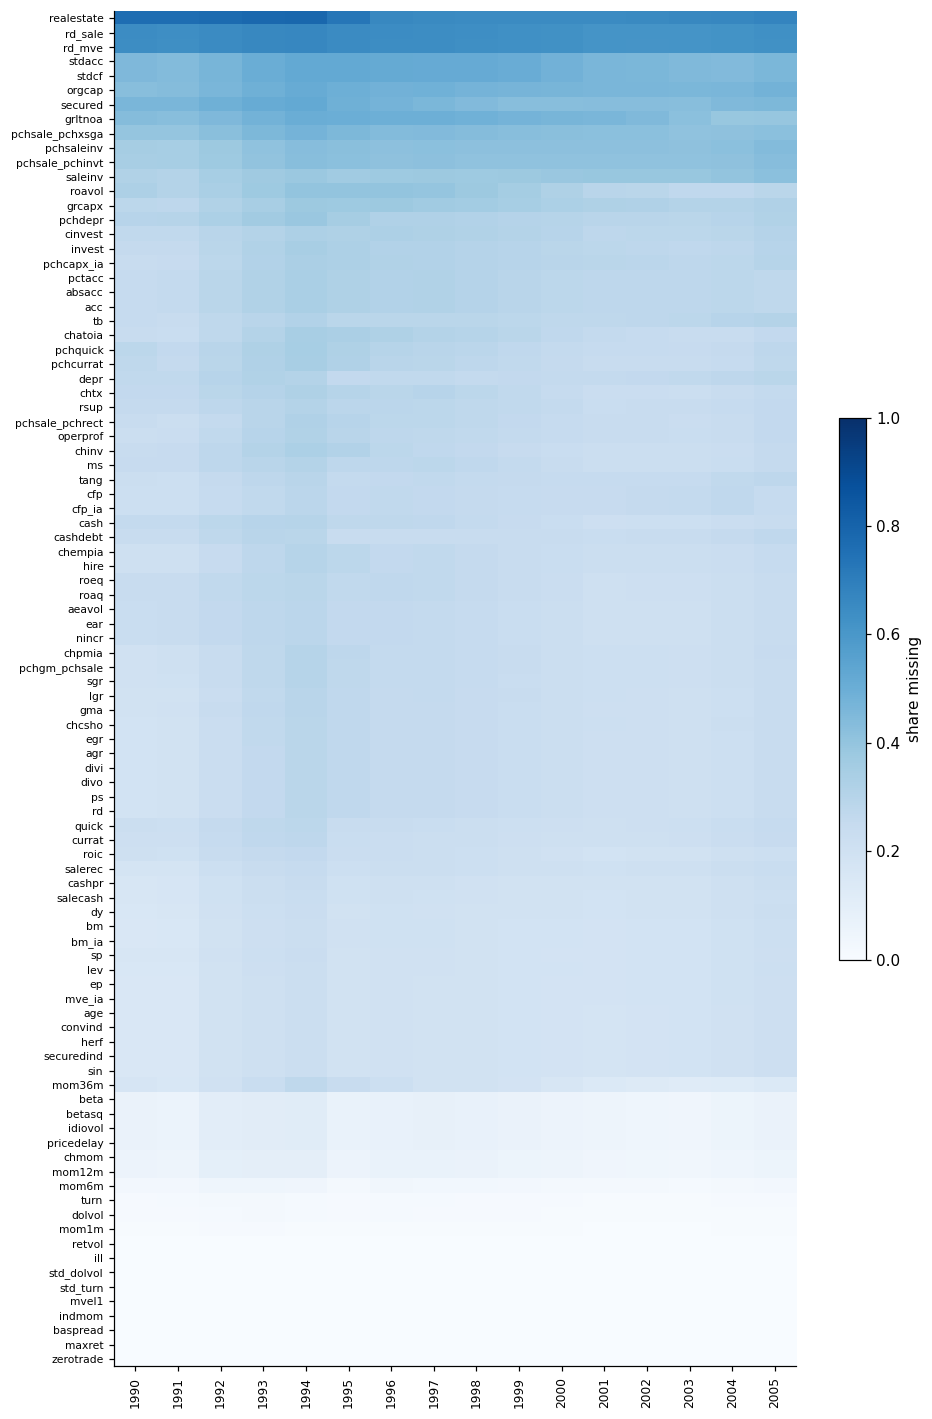

In [6]:
by_year = (df.with_columns((pl.col("DATE") // 10000).alias("year")).group_by("year")
             .agg([pl.col(c).is_null().mean() for c in chars]).sort("year"))
order = miss["char"].to_list()
mat = by_year.select(order).to_numpy().T
fig, ax = plt.subplots(figsize=(10, 16))
im = ax.imshow(mat, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(order)), order, fontsize=7)
ax.set_xticks(range(by_year.height), by_year["year"], rotation=90, fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, label="share missing", shrink=0.4); plt.show()

## Number of missing characteristics per firm-month

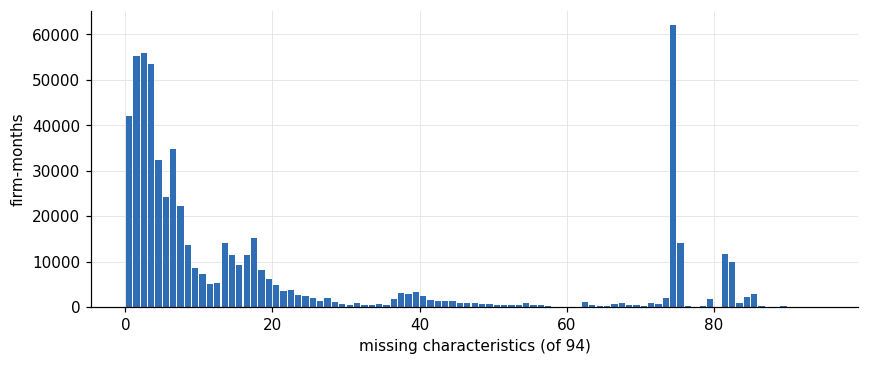

n_missing_bucket,len,share
u32,u32,f64
0,342611,0.5637
10,93509,0.1538
20,24580,0.0404
30,14467,0.0238
40,12655,0.0208
50,4435,0.0073
60,4875,0.0080
70,82362,0.1355
80,28328,0.0466


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df["n_missing"], bins=range(0, len(chars) + 2), color=BLUE, rwidth=0.85)
ax.set_xlabel(f"missing characteristics (of {len(chars)})"); ax.set_ylabel("firm-months"); plt.show()
(df.group_by((pl.col("n_missing") // 10 * 10).alias("n_missing_bucket")).len().sort("n_missing_bucket")
   .with_columns((pl.col("len") / df.height).alias("share")))

## Share of rows removed by a row-level missingness cutoff

In [8]:
cutoffs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
pl.DataFrame({"max_missing_share": cutoffs,
              "rows_removed": [(df["n_missing"] > c * len(chars)).mean() for c in cutoffs]})

max_missing_share,rows_removed
f64,f64
0.1000,0.4363
0.2000,0.2925
0.3000,0.2432
0.4000,0.2283
0.5000,0.1999
0.6000,0.1909
0.7000,0.1865
0.8000,0.0500
0.9000,0.0055


## Profile of firm-months with more than half the characteristics missing

In [9]:
first_seen = lf.group_by("permno").agg(pl.col("DATE").min().alias("first_date")).collect()
prof = df.join(first_seen, on="permno").with_columns(
    (pl.col("n_missing") > len(chars) / 2).alias("over_half_missing"),
    ((pl.col("DATE") // 10000 - pl.col("first_date") // 10000) * 12
     + (pl.col("DATE") // 100 % 100 - pl.col("first_date") // 100 % 100)).alias("months_in_panel"),
)
prof.group_by("over_half_missing").agg(
    pl.len().alias("rows"),
    pl.col("months_in_panel").median().alias("median_months_in_panel"),
    pl.col("mvel1").median().alias("median_mvel1"),
    (pl.col("first_date") == pl.col("first_date").min()).mean().alias("share_in_panel_from_start"),
    pl.col("ret").mean().alias("mean_ret"), pl.col("ret").std().alias("std_ret"),
).sort("over_half_missing")

over_half_missing,rows,median_months_in_panel,median_mvel1,share_in_panel_from_start,mean_ret,std_ret
bool,u32,f64,f64,f64,f64,f64
false,486292,70.0000,521147.1232,0.6358,0.0135,0.1353
true,121530,31.0000,172449.2134,0.2750,0.0089,0.1053


## Which characteristics are present in firm-months with more than half missing

In [10]:
hi = df.filter(pl.col("n_missing") > len(chars) / 2)
(hi.select([pl.col(c).is_not_null().mean().alias(c) for c in chars])
   .transpose(include_header=True, header_name="char", column_names=["present"])
   .filter(pl.col("present") > 0.5).sort("present", descending=True))

char,present
str,f64
"""mvel1""",1.0000
"""indmom""",1.0000
"""baspread""",1.0000
"""maxret""",1.0000
"""zerotrade""",1.0000
"""ill""",0.9985
"""std_dolvol""",0.9985
"""std_turn""",0.9985
"""retvol""",0.9971


## Missing share per characteristic after removing rows with more than half missing

In [11]:
kept = df.filter(pl.col("n_missing") <= len(chars) / 2)
miss_kept = (kept.select([pl.col(c).is_null().mean().alias(c) for c in chars])
               .transpose(include_header=True, header_name="char", column_names=["missing_after_row_filter"]))
miss.join(miss_kept, on="char").sort("missing_after_row_filter", descending=True)

char,missing,missing_after_row_filter
str,f64,f64
"""realestate""",0.6922,0.6177
"""rd_sale""",0.6368,0.5490
"""rd_mve""",0.6354,0.5474
"""stdacc""",0.4832,0.3591
"""stdcf""",0.4832,0.3591
"""orgcap""",0.4722,0.3403
"""secured""",0.4588,0.3292
"""grltnoa""",0.4584,0.3230
"""pchsale_pchxsga""",0.4293,0.2866


## Columns above a missingness cutoff (after row filter)

In [12]:
pl.DataFrame([{"cutoff": c, "n_columns_above": (miss_kept["missing_after_row_filter"] > c).sum(),
               "columns": ", ".join(miss_kept.filter(pl.col("missing_after_row_filter") > c).sort("missing_after_row_filter", descending=True)["char"])}
              for c in [0.5, 0.4, 0.3, 0.2]])

cutoff,n_columns_above,columns
f64,i64,str
0.5000,3,"""realestate, rd_sale, rd_mve"""
0.4000,3,"""realestate, rd_sale, rd_mve"""
0.3000,8,"""realestate, rd_sale, rd_mve, s…"
0.2000,12,"""realestate, rd_sale, rd_mve, s…"


## Size cutoff: computed on all firm-months vs only firm-months with a return

In [13]:
base = lf.filter(pl.col("DATE") <= IS_END_DATE)
cut_all = base.group_by("DATE").agg(pl.col("mvel1").quantile(MIN_SIZE_QUANTILE).alias("cut_all"))
cut_ret = (base.join(ret_keys, on=["permno", "ym"], how="semi").group_by("DATE")
               .agg(pl.col("mvel1").quantile(MIN_SIZE_QUANTILE).alias("cut_with_return")))
order_a = size_zerotrade_filter(base).join(ret_keys, on=["permno", "ym"], how="semi").select(pl.len()).collect().item()
order_b = size_zerotrade_filter(base.join(ret_keys, on=["permno", "ym"], how="semi")).select(pl.len()).collect().item()
print("rows: filter then join returns =", order_a, "| join returns then filter =", order_b)
cut_all.join(cut_ret, on="DATE").collect().select(pl.col("cut_all", "cut_with_return").median())

rows: filter then join returns = 607822 | join returns then filter = 532728


cut_all,cut_with_return
f64,f64
23563.6801,70703.0000
